# Lab 3 - Supervised vs Unsupervised Anomaly Detection

Notebook structure follows the assignment tasks. Training runs are numbered as in `LOGBOOK.md`; answers are in `NOTES.md`.

In [1]:
import random, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

SEED = 42
random.seed(SEED); np.random.seed(SEED)
pd.set_option('display.max_columns', 60)

TRAIN_PATH, TEST_PATH = 'Lab3_train.csv', 'Lab3_test.csv'
train_raw = pd.read_csv(TRAIN_PATH)
test_raw  = pd.read_csv(TEST_PATH)
print('train', train_raw.shape, '| test', test_raw.shape)

train (18831, 43) | test (5826, 43)


## Task 1 - The data from a domain-expert perspective

### Task 1.1 - Explore the dataset

In [2]:
LABEL, BIN = 'label', 'binary_label'
FEATURES = [c for c in train_raw.columns if c not in (LABEL, BIN)]
CAT_COLS = [c for c in FEATURES if not pd.api.types.is_numeric_dtype(train_raw[c])]
NUM_COLS = [c for c in FEATURES if c not in CAT_COLS]
BIN01_COLS = [c for c in NUM_COLS if set(train_raw[c].unique()) <= {0, 1}]
print(f'{len(FEATURES)} features: {len(CAT_COLS)} categorical, {len(NUM_COLS)} numerical (0/1 counted as numerical)')
print('Categorical:', CAT_COLS)
print('0/1 numerical:', BIN01_COLS)
for c in CAT_COLS:
    unseen = sorted(set(test_raw[c]) - set(train_raw[c]))
    print(f'{c}: {train_raw[c].nunique()} levels in train, {test_raw[c].nunique()} in test; unseen in test: {unseen}')

41 features: 3 categorical, 38 numerical (0/1 counted as numerical)
Categorical: ['protocol_type', 'service', 'flag']
0/1 numerical: ['land', 'urgent', 'logged_in', 'root_shell', 'num_shells', 'num_outbound_cmds', 'is_host_login', 'is_guest_login']
protocol_type: 3 levels in train, 3 in test; unseen in test: []
service: 65 levels in train, 61 in test; unseen in test: ['tftp_u', 'tim_i']
flag: 11 levels in train, 11 in test; unseen in test: []


In [3]:
def label_table(df):
    t = pd.DataFrame({'count': df[LABEL].value_counts(), '%': (df[LABEL].value_counts(normalize=True)*100).round(2)})
    return t

dist = pd.concat({'train': label_table(train_raw), 'test': label_table(test_raw)}, axis=1).fillna(0)
display(dist)
for name, df in [('train', train_raw), ('test', test_raw)]:
    n_anom = df[BIN].sum()
    print(f'{name}: normal={len(df)-n_anom}, anomalous={n_anom}, anomaly fraction={n_anom/len(df):.4f}')
    # consistency between attack label and binary label
    assert ((df[LABEL] != 'normal').astype(int) == df[BIN]).all()

train           test       
        count      %   count      %
label                              
normal  13448  71.41  2152.0  36.94
dos      2913  15.47  2577.0  44.23
probe    2289  12.16  1097.0  18.83
r2l       181   0.96     0.0   0.00

train: normal=13448, anomalous=5383, anomaly fraction=0.2859
test: normal=2152, anomalous=3674, anomaly fraction=0.6306


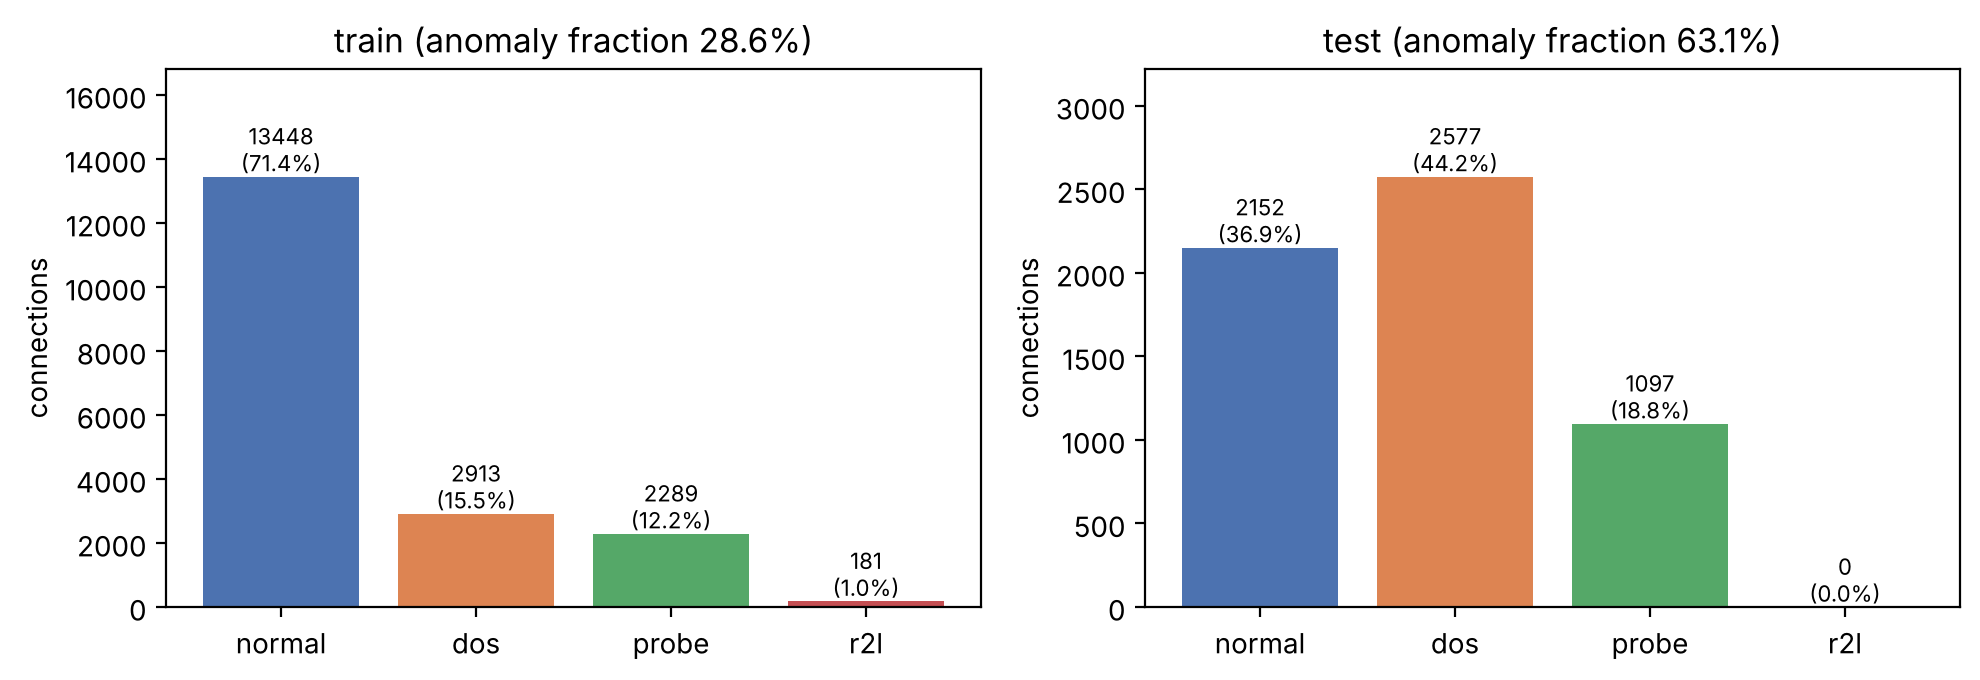

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5))
order = ['normal', 'dos', 'probe', 'r2l']
for ax, (name, df) in zip(axes, [('train', train_raw), ('test', test_raw)]):
    vc = df[LABEL].value_counts().reindex(order, fill_value=0)
    ax.bar(vc.index, vc.values, color=['#4C72B0', '#DD8452', '#55A868', '#C44E52'])
    for i, v in enumerate(vc.values):
        ax.text(i, v, f'{v}\n({v/len(df):.1%})', ha='center', va='bottom', fontsize=8)
    ax.set_title(f'{name} (anomaly fraction {df[BIN].mean():.1%})'); ax.set_ylabel('connections')
    ax.set_ylim(0, vc.max()*1.25)
plt.tight_layout(); plt.show()

In [5]:
# Data quality checks (no rows are modified here)
for name, df in [('train', train_raw), ('test', test_raw)]:
    num = df[NUM_COLS]
    print(f'{name}: missing={df.isna().sum().sum()}, inf={np.isinf(num).sum().sum()}, '
          f'negative={(num < 0).sum().sum()}, duplicate rows={df.duplicated().sum()}, '
          f'duplicate feature vectors={df[FEATURES].duplicated().sum()}')
    print('   constant numerical columns:', [c for c in NUM_COLS if df[c].nunique() == 1])
conf = train_raw[train_raw.duplicated(FEATURES, keep=False)]
print('\nFeature vectors with conflicting labels in train:'); display(conf[['protocol_type','service','flag','src_bytes',LABEL]])
overlap = test_raw.merge(train_raw, how='inner', on=list(train_raw.columns))
print('Test rows identical to a training row:', len(overlap))

train: missing=0, inf=0, negative=0, duplicate rows=0, duplicate feature vectors=1
   constant numerical columns: ['urgent', 'num_outbound_cmds', 'is_host_login']
test: missing=0, inf=0, negative=0, duplicate rows=0, duplicate feature vectors=0
   constant numerical columns: ['land', 'urgent', 'num_shells', 'num_outbound_cmds', 'is_host_login']

Feature vectors with conflicting labels in train:


,protocol_type,service,flag,src_bytes,label
8087,icmp,ecr_i,SF,20,probe
8800,icmp,ecr_i,SF,20,normal


Test rows identical to a training row: 75


In [6]:
print('Protocol by label (train):'); display(pd.crosstab(train_raw[LABEL], train_raw['protocol_type']))
print('Heavy-tailed numerical features (train):')
display(train_raw[NUM_COLS].describe().T.query('max > 1')[['mean','50%','max']].sort_values('max', ascending=False))

Protocol by label (train):


protocol_type,icmp,tcp,udp
label,,,
dos,529,2196,188
normal,261,10680,2507
probe,827,1147,315
r2l,0,181,0


Heavy-tailed numerical features (train):


,mean,50%,max
src_bytes,32545.325155,207.0,381709090.0
dst_bytes,3238.092719,136.0,5131424.0
duration,407.959057,0.0,42862.0
num_root,0.330253,0.0,975.0
num_compromised,0.301630,0.0,884.0
count,55.027508,6.0,511.0
srv_count,33.330891,6.0,511.0
dst_host_srv_count,149.129149,188.0,255.0
dst_host_count,161.085126,222.0,255.0
hot,0.261324,0.0,77.0
